In [1]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import random
from torch.utils.data import Dataset
from collections import defaultdict
from tqdm import tqdm

# 1. Config

In [2]:
config = {
    "data_train_valid_path": "/kaggle/input/datasets/nhatanhadr/xes3g5m/train_valid_sequences.csv",
    "data_test_path": "/kaggle/input/datasets/nhatanhadr/xes3g5m/test_question_window_sequences.csv",
    "num_concepts": 865,
    "embed_dim": 100,
    "hidden_dim": 200,
    "dropout": 0.2,
    "lr": 1e-3,
    "batch_size": 128,
    "num_epochs": 100,
    "patience": 10,
}

# 2. Data Loading

In [3]:
df_train_valid = pd.read_csv(config["data_train_valid_path"])
df_test = pd.read_csv(config["data_test_path"])

print(f"Train: {len(df_train_valid)}")
print(f"Test: {len(df_test)}")

Train: 33397
Test: 697697


# 3. Dataset and DataLoader

In [4]:
def parse_seq(s):
    return list(map(int, s.strip().split(',')))

class DKTDataset():
    def __init__(self, df, fold=None, is_train=True):
        if fold is not None:
            if is_train:
                df = df[df['fold'] != fold]
            else:
                df = df[df['fold'] == fold]
        self.concepts = [parse_seq(x) for x in df['concepts']]
        self.responses = [parse_seq(x) for x in df['responses']]
        self.selectmasks = [parse_seq(x) for x in df['selectmasks']]
        self.is_repeat = [parse_seq(x) for x in df['is_repeat']]

        # Only in test
        self.qidxs = (
            [parse_seq(x) for x in df['qidxs']]
            if 'qidxs' in df.columns else [None]*len(df)
        )

        self.rest = (
            [parse_seq(x) for x in df['rest']]
            if 'rest' in df.columns else [None]*len(df)
        )

        self.len = len(df)

    def __len__(self):
        return self.len

    def __getitem__(self, i):
        c = torch.tensor(self.concepts[i], dtype=torch.long).clamp(min=0)
        r = torch.tensor(self.responses[i], dtype=torch.long).clamp(min=0)
        m = torch.tensor(self.selectmasks[i], dtype=torch.long)

        item = {
            "concepts": c,
            "responses": r,
            "selectmasks": m
        }

        if self.qidxs[i] is not None:
            item["qidxs"] = torch.tensor(self.qidxs[i], dtype=torch.long)

        if self.rest[i] is not None:
            item["rest"] = torch.tensor(self.rest[i], dtype=torch.long)

        return item

# 4. Model Definition

In [5]:
class DKT(nn.Module):

    def __init__(self, num_concepts, embed_dim=128, hidden_dim=256, dropout=0.2):
        super(DKT, self).__init__()
        self.num_concepts = num_concepts
        self.embed_dim = embed_dim
        self.hidden_dim = hidden_dim
        self.interaction_embed = nn.Embedding(num_concepts * 2, embed_dim)
        self.lstm_layer = nn.LSTM(embed_dim, hidden_dim, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.out_layer = nn.Linear(hidden_dim, num_concepts)
        
    def forward(self, c, r):
        x = c + self.num_concepts * r # x in (B, L)
        x_embed = self.interaction_embed(x) # x_embed in (B, L, embed_dim)

        h, _ = self.lstm_layer(x_embed) # h in (B, L, hidden_dim)
        h_shift = torch.zeros_like(h) # h_shift in (B, L, hidden_dim)
        h_shift[:, 1:, :] = h[:, :-1, :] # h_shift in (B, L, hidden_dim)

        h_shift = self.dropout(h_shift)

        logits = self.out_layer(h_shift) # logits in (B, L, num_concepts)
        
        return logits

# 5. Compute Metric

In [6]:
import numpy as np
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    mean_squared_error,
    brier_score_loss,
    average_precision_score,
    f1_score,
)


def expected_calibration_error(y_true, y_prob, n_bins=10):
    """ECE với các bin có độ rộng bằng nhau trên [0, 1]."""
    y_true = np.asarray(y_true)
    y_prob = np.asarray(y_prob)

    bins = np.linspace(0.0, 1.0, n_bins + 1)
    # digitize trả về 1..n_bins+1; đưa về chỉ số 0..n_bins-1
    bin_ids = np.clip(np.digitize(y_prob, bins[1:-1], right=True), 0, n_bins - 1)

    ece = 0.0
    n = len(y_true)
    for b in range(n_bins):
        mask = bin_ids == b
        if not mask.any():
            continue
        acc_bin = y_true[mask].mean()      # tần suất "đúng" thực tế trong bin
        conf_bin = y_prob[mask].mean()     # xác suất dự đoán trung bình trong bin
        ece += (mask.sum() / n) * abs(acc_bin - conf_bin)
    return float(ece)


def compute_metrics(y_true, y_pred, threshold=0.5, n_bins=10):
    """
    y_true: nhãn thật (1 = trả lời đúng, 0 = trả lời sai)
    y_pred: xác suất dự đoán P(đúng)
    """
    y_true = np.asarray(y_true).astype(int)
    y_pred = np.asarray(y_pred).astype(float)
    y_pred_binary = (y_pred > threshold).astype(int)

    has_both_classes = len(np.unique(y_true)) > 1

    # --- Nhóm giống pyKT ---
    auc = roc_auc_score(y_true, y_pred) if has_both_classes else 0.5
    acc = accuracy_score(y_true, y_pred_binary)
    rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))

    # --- Nhóm hiệu chỉnh xác suất ---
    brier = brier_score_loss(y_true, y_pred)
    ece = expected_calibration_error(y_true, y_pred, n_bins=n_bins)

    # --- Nhóm cho lớp "sai" (lớp 0, lớp thiểu số ~20%) ---
    # Với lớp "sai" làm lớp dương: nhãn = 1 - y_true, điểm = 1 - P(đúng)
    y_wrong = 1 - y_true
    p_wrong = 1.0 - y_pred
    wrong_pred_binary = 1 - y_pred_binary

    auprc_wrong = (
        average_precision_score(y_wrong, p_wrong) if has_both_classes else float(y_wrong.mean())
    )
    f1_wrong = f1_score(y_wrong, wrong_pred_binary, zero_division=0)

    return {
        "auc": auc,
        "acc": acc,
        "rmse": rmse,
        "brier": brier,
        "ece": ece,
        "auprc_wrong": auprc_wrong,
        "f1_wrong": f1_wrong,
    }

# 6. Evaluate

In [7]:
def dkt_evaluate(model, loader, device, question_level=True):
    model.eval()

    if question_level:
        q_preds = defaultdict(list)
        q_labels = defaultdict(list)
    else:
        all_preds = []
        all_labels = []

    loss_sum, n_valid = 0.0, 0
    criterion = nn.BCEWithLogitsLoss(reduction="sum")

    with torch.no_grad():
        for batch in tqdm(loader, desc="Evaluating", leave=False):
            concepts = batch["concepts"].to(device)
            responses = batch["responses"].to(device)
            selectmasks = batch["selectmasks"].to(device)

            if question_level and "qidxs" not in batch:
                raise ValueError("Dataset doesn't have 'qidxs' so it can not evaluate at question level.")

            logits = model(concepts, responses) # (B, L, num_concepts)
            B, L, _ = logits.shape

            batch_idx = torch.arange(B, device=logits.device).unsqueeze(1)  # (B, 1)
            time_idx  = torch.arange(L, device=logits.device).unsqueeze(0)  # (1, L)
            logits_selected = logits[batch_idx, time_idx, concepts]         # (B, L)
            preds = torch.sigmoid(logits_selected) # (B, L)

            mask = selectmasks.clone()
            mask[:, 0] = -1
            valid = mask == 1

            loss_sum += criterion(logits_selected[valid], responses[valid].float()).item()
            n_valid += valid.sum().item()

            if question_level:
                qidxs = batch["qidxs"]
                rest = batch["rest"]
                preds_cpu = preds.cpu()
                targets_cpu = responses.cpu()
                valid_cpu = valid.cpu()
                qidxs_cpu = qidxs.cpu()
                rest_cpu = rest.cpu()

                B, L = preds.shape
                for i in range(B):
                    for t in range(L):
                        if valid_cpu[i, t]:
                            qid = qidxs_cpu[i, t].item()
                            q_preds[qid].append((preds_cpu[i, t].item(), rest_cpu[i, t].item()))
                            q_labels[qid].append(targets_cpu[i, t].item())

            else:
                all_preds.extend(preds[valid].cpu().numpy().tolist())
                all_labels.extend(responses[valid].cpu().numpy().tolist())
        if question_level:
            final_preds, final_trues = [], []

            # Check qidxs is valid by rest
            for qid, values in q_preds.items():
                rests = sorted(rest for pred, rest in values)

                if not rests == list(range(len(values))):
                    print(qid, "Not valid")

                pred_list = [p for p, _ in values]
                final_preds.append(float(np.mean(pred_list)))
                final_trues.append(int(np.mean(q_labels[qid]) >= 0.5))

            metrics = compute_metrics(final_trues, final_preds)
        else:
            metrics = compute_metrics(all_labels, all_preds)

        
    metrics["loss"] = loss_sum / max(n_valid, 1)
    return metrics

# 7. DKT Train Loop

In [8]:
def dkt_train_epoch(model, train_loader, valid_loader, optimizer, device, num_epochs=100, patience=5):

    train_loss_history = []
    valid_loss_history = []
    valid_auc_history = []

    best_auc = 0.0
    best_state = None
    no_improve = 0

    for epoch in range(num_epochs):
        # Train
        model.train()
        total_loss = 0.0
        n_valid = 0

        pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs} - Train", leave=False)
        for batch in pbar:
            concepts = batch["concepts"].to(device)
            responses = batch["responses"].to(device)
            selectmasks = batch["selectmasks"].to(device)

            optimizer.zero_grad(set_to_none=True)

            logits = model(concepts, responses) # logits in (B, L, num_concepts)
            B, L, _ = logits.shape

            batch_idx = torch.arange(B, device=logits.device).unsqueeze(1)
            time_idx = torch.arange(L, device=logits.device).unsqueeze(0)
            logits_selected = logits[batch_idx, time_idx, concepts] # logits_selected in (B, L)

            criterion = nn.BCEWithLogitsLoss(reduction="sum")

            mask = selectmasks.clone()
            mask[:, 0] = -1
            valid = mask == 1

            n = valid.sum()
            loss = criterion(logits_selected[valid], responses[valid].float())
            (loss / n.clamp(min=1)).backward()
            optimizer.step()

            total_loss += loss.item()
            n_valid += n.item()
            pbar.set_postfix(loss=loss.item())

        avg_train_loss = total_loss / n_valid
        train_loss_history.append(avg_train_loss)

        # Valid
        val_metrics = dkt_evaluate(model, valid_loader, device, question_level=False)
        avg_val_loss = val_metrics["loss"]
        valid_loss_history.append(avg_val_loss)
        valid_auc_history.append(val_metrics["auc"])

        print(f"Epoch {epoch+1}: train_loss={avg_train_loss:.4f}, "
              f"val_loss={avg_val_loss:.4f}, val_auc={val_metrics['auc']:.4f}, "
              f"val_acc={val_metrics['acc']:.4f}")

        # Early stopping
        if val_metrics["auc"] > best_auc:
            best_auc = val_metrics["auc"]
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            no_improve = 0
        else:
            no_improve += 1
            if no_improve >= patience:
                print(f"Early stopping tại epoch {epoch+1}")
                break
            
    if best_state is not None:
        model.load_state_dict(best_state)

    history = {
        "train_loss": train_loss_history,
        "valid_loss": valid_loss_history,
        "valid_auc": valid_auc_history,
        "best_auc": best_auc
    }

    return model, history

# 8. Training and Evaluating


FOLD 0


Epoch 1: train_loss=0.4348, val_loss=0.3882, val_auc=0.8117, val_acc=0.8330


Epoch 2: train_loss=0.3817, val_loss=0.3767, val_auc=0.8233, val_acc=0.8373


Epoch 3: train_loss=0.3737, val_loss=0.3726, val_auc=0.8278, val_acc=0.8386


Epoch 4: train_loss=0.3695, val_loss=0.3703, val_auc=0.8299, val_acc=0.8394


...

Epoch 17: train_loss=0.3456, val_loss=0.3659, val_auc=0.8342, val_acc=0.8409


Epoch 18: train_loss=0.3440, val_loss=0.3669, val_auc=0.8340, val_acc=0.8409


Epoch 19: train_loss=0.3425, val_loss=0.3674, val_auc=0.8330, val_acc=0.8401


Epoch 20: train_loss=0.3410, val_loss=0.3679, val_auc=0.8328, val_acc=0.8402


Epoch 21: train_loss=0.3396, val_loss=0.3683, val_auc=0.8323, val_acc=0.8401
Early stopping tại epoch 21


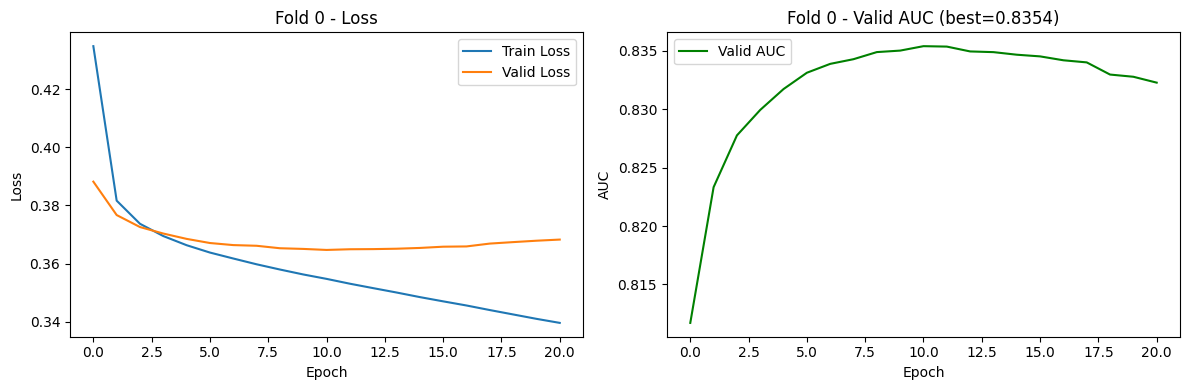

Fold 0 xong. Best valid AUC = 0.8354

FOLD 1


Epoch 1: train_loss=0.4372, val_loss=0.3862, val_auc=0.8125, val_acc=0.8342


Epoch 2: train_loss=0.3821, val_loss=0.3755, val_auc=0.8237, val_acc=0.8384


Epoch 3: train_loss=0.3743, val_loss=0.3706, val_auc=0.8283, val_acc=0.8401


Epoch 4: train_loss=0.3700, val_loss=0.3682, val_auc=0.8308, val_acc=0.8409


...

Epoch 19: train_loss=0.3433, val_loss=0.3655, val_auc=0.8339, val_acc=0.8421


Epoch 20: train_loss=0.3419, val_loss=0.3660, val_auc=0.8336, val_acc=0.8418


Epoch 21: train_loss=0.3403, val_loss=0.3664, val_auc=0.8327, val_acc=0.8414


Epoch 22: train_loss=0.3389, val_loss=0.3669, val_auc=0.8323, val_acc=0.8410


Epoch 23: train_loss=0.3373, val_loss=0.3680, val_auc=0.8319, val_acc=0.8405
Early stopping tại epoch 23


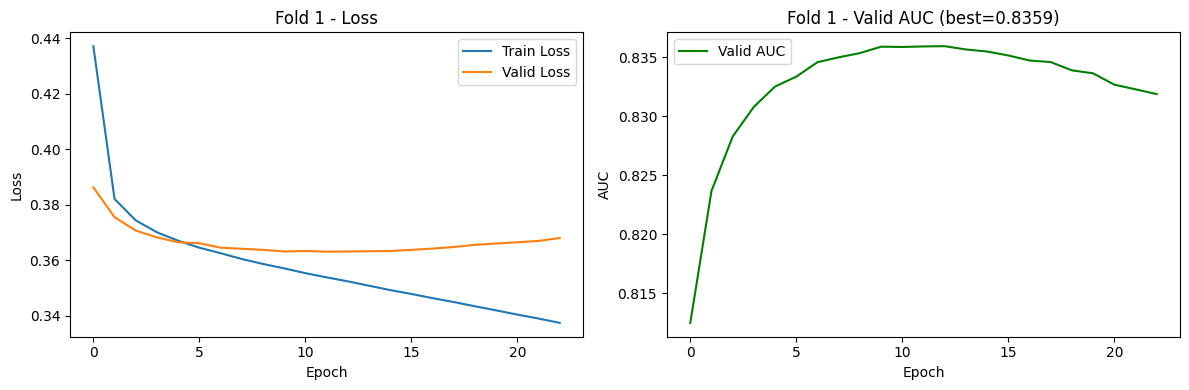

Fold 1 xong. Best valid AUC = 0.8359

FOLD 2


Epoch 1: train_loss=0.4366, val_loss=0.3902, val_auc=0.8140, val_acc=0.8308


Epoch 2: train_loss=0.3825, val_loss=0.3778, val_auc=0.8266, val_acc=0.8356


Epoch 3: train_loss=0.3746, val_loss=0.3739, val_auc=0.8305, val_acc=0.8375


Epoch 4: train_loss=0.3704, val_loss=0.3708, val_auc=0.8335, val_acc=0.8383


...

Epoch 19: train_loss=0.3441, val_loss=0.3668, val_auc=0.8377, val_acc=0.8391


Epoch 20: train_loss=0.3426, val_loss=0.3670, val_auc=0.8369, val_acc=0.8396


Epoch 21: train_loss=0.3412, val_loss=0.3674, val_auc=0.8371, val_acc=0.8395


Epoch 22: train_loss=0.3397, val_loss=0.3680, val_auc=0.8363, val_acc=0.8391


Epoch 23: train_loss=0.3381, val_loss=0.3688, val_auc=0.8358, val_acc=0.8390
Early stopping tại epoch 23


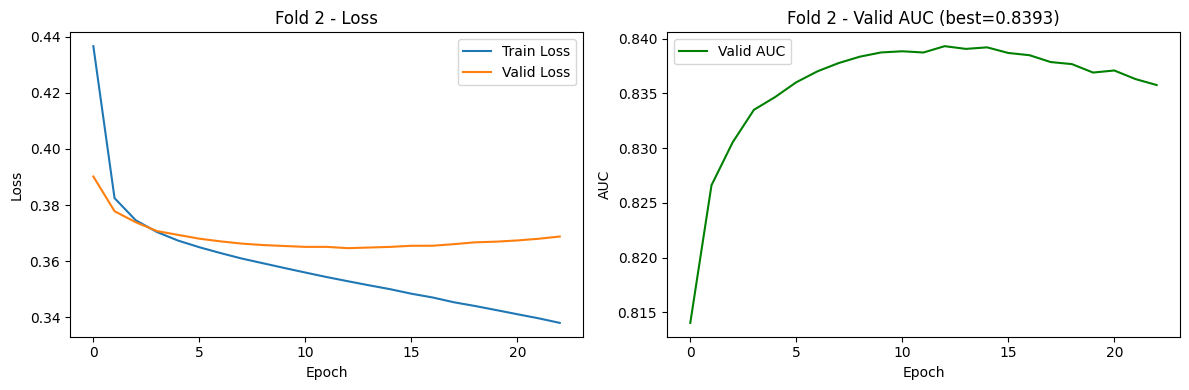

Fold 2 xong. Best valid AUC = 0.8393

FOLD 3


Epoch 1: train_loss=0.4370, val_loss=0.3844, val_auc=0.8143, val_acc=0.8351


Epoch 2: train_loss=0.3821, val_loss=0.3738, val_auc=0.8250, val_acc=0.8391


Epoch 3: train_loss=0.3743, val_loss=0.3697, val_auc=0.8289, val_acc=0.8406


Epoch 4: train_loss=0.3700, val_loss=0.3673, val_auc=0.8314, val_acc=0.8415


...

Epoch 18: train_loss=0.3453, val_loss=0.3640, val_auc=0.8350, val_acc=0.8422


Epoch 19: train_loss=0.3439, val_loss=0.3644, val_auc=0.8346, val_acc=0.8420


Epoch 20: train_loss=0.3423, val_loss=0.3649, val_auc=0.8340, val_acc=0.8416


Epoch 21: train_loss=0.3408, val_loss=0.3660, val_auc=0.8334, val_acc=0.8417


Epoch 22: train_loss=0.3394, val_loss=0.3664, val_auc=0.8328, val_acc=0.8411
Early stopping tại epoch 22


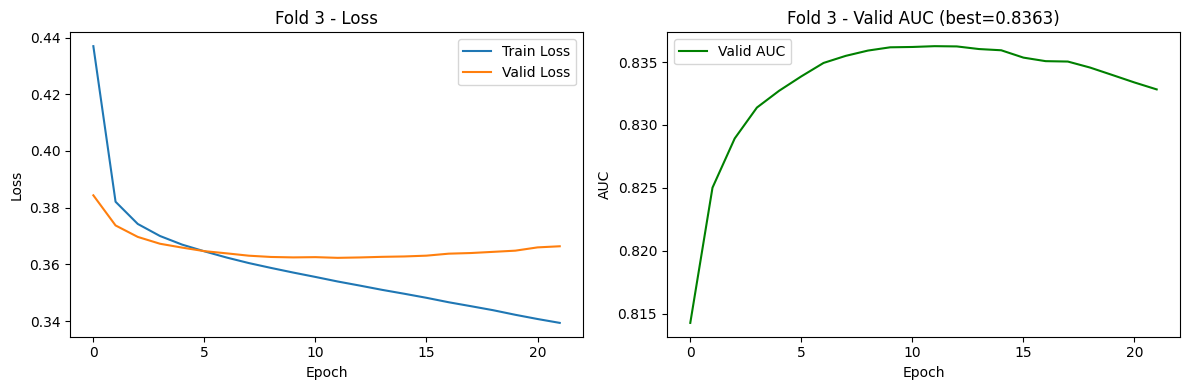

Fold 3 xong. Best valid AUC = 0.8363

FOLD 4


Epoch 1: train_loss=0.4360, val_loss=0.3873, val_auc=0.8140, val_acc=0.8328


Epoch 2: train_loss=0.3811, val_loss=0.3765, val_auc=0.8250, val_acc=0.8368


Epoch 3: train_loss=0.3735, val_loss=0.3724, val_auc=0.8288, val_acc=0.8380


Epoch 4: train_loss=0.3693, val_loss=0.3699, val_auc=0.8313, val_acc=0.8391


...

Epoch 18: train_loss=0.3443, val_loss=0.3667, val_auc=0.8345, val_acc=0.8403


Epoch 19: train_loss=0.3427, val_loss=0.3674, val_auc=0.8340, val_acc=0.8396


Epoch 20: train_loss=0.3414, val_loss=0.3682, val_auc=0.8335, val_acc=0.8399


Epoch 21: train_loss=0.3398, val_loss=0.3686, val_auc=0.8332, val_acc=0.8395


Epoch 22: train_loss=0.3383, val_loss=0.3697, val_auc=0.8327, val_acc=0.8393
Early stopping tại epoch 22


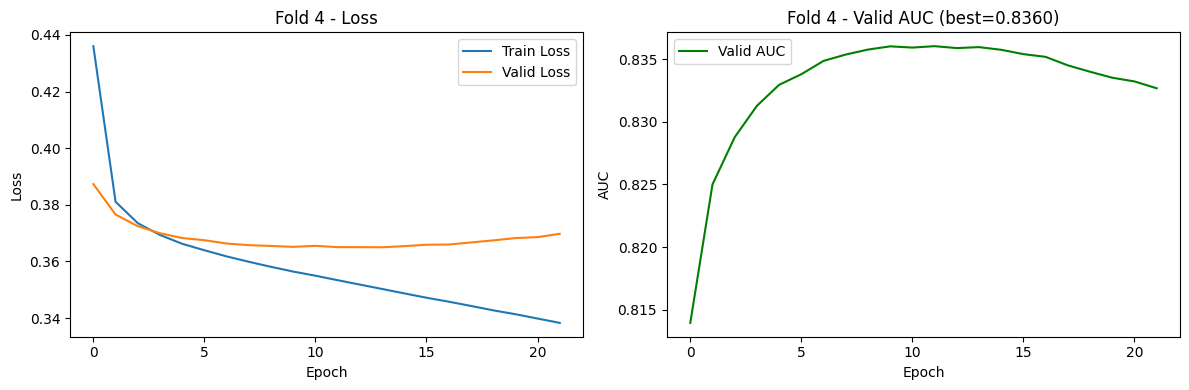

Fold 4 xong. Best valid AUC = 0.8360


In [9]:
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader

trained_models = []
all_histories = []

for i in range(5):
    print(f"\n{'='*50}\nFOLD {i}\n{'='*50}")

    train_dataset = DKTDataset(df_train_valid, fold=i, is_train=True)
    valid_dataset = DKTDataset(df_train_valid, fold=i, is_train=False)
    train_loader = DataLoader(train_dataset, batch_size=config["batch_size"], shuffle=True)
    valid_loader = DataLoader(valid_dataset, batch_size=config["batch_size"], shuffle=False)

    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

    model = DKT(
        num_concepts=config.get('num_concepts', 100),
        embed_dim=config.get('embed_dim', 100),
        hidden_dim=config.get('hidden_dim', 200),
        dropout=config.get('dropout', 0.2)
    ).to(device)

    optimizer = torch.optim.Adam(model.parameters(), lr=config.get('lr', 1e-3))

    model, history = dkt_train_epoch(
        model, train_loader, valid_loader, optimizer, device,
        num_epochs=config.get('num_epochs', 50),
        patience=config.get('patience', 5)
    )

    trained_models.append(model)
    all_histories.append(history)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(history["train_loss"], label="Train Loss")
    axes[0].plot(history["valid_loss"], label="Valid Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].set_title(f"Fold {i} - Loss")
    axes[0].legend()

    axes[1].plot(history["valid_auc"], label="Valid AUC", color="green")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("AUC")
    axes[1].set_title(f"Fold {i} - Valid AUC (best={history['best_auc']:.4f})")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

    print(f"Fold {i} xong. Best valid AUC = {history['best_auc']:.4f}")

Fold 0 - Test: auc=0.7845, acc=0.8173, rmse=0.3630, brier=0.1318, ece=0.0098, auprc_wrong=0.5080, f1_wrong=0.3822, loss=0.4288


Fold 1 - Test: auc=0.7839, acc=0.8167, rmse=0.3634, brier=0.1321, ece=0.0128, auprc_wrong=0.5070, f1_wrong=0.3937, loss=0.4318


Fold 2 - Test: auc=0.7845, acc=0.8171, rmse=0.3631, brier=0.1318, ece=0.0093, auprc_wrong=0.5077, f1_wrong=0.3838, loss=0.4311


Fold 3 - Test: auc=0.7844, acc=0.8171, rmse=0.3631, brier=0.1319, ece=0.0102, auprc_wrong=0.5080, f1_wrong=0.3879, loss=0.4298


Fold 4 - Test: auc=0.7843, acc=0.8169, rmse=0.3632, brier=0.1319, ece=0.0112, auprc_wrong=0.5078, f1_wrong=0.3866, loss=0.4300

TỔNG HỢP KẾT QUẢ TEST (5-fold)
AUC       : 0.7843 ± 0.0002
ACC       : 0.8170 ± 0.0002
RMSE      : 0.3632 ± 0.0001
BRIER     : 0.1319 ± 0.0001
ECE       : 0.0107 ± 0.0012
AUPRC_WRONG: 0.5077 ± 0.0004
F1_WRONG  : 0.3868 ± 0.0040


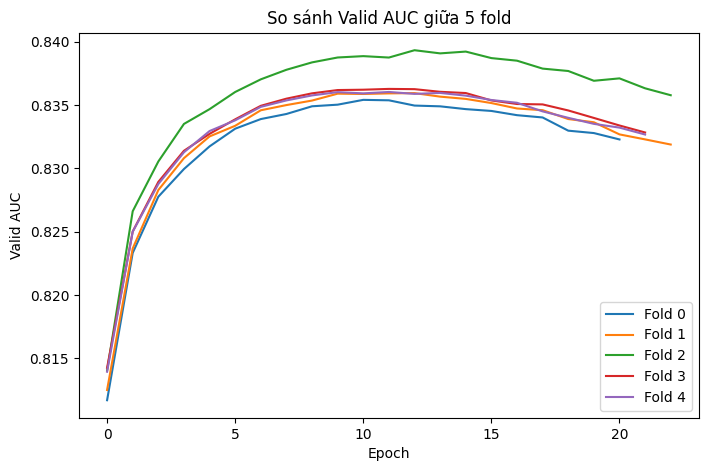

In [10]:
test_dataset = DKTDataset(df_test, fold=None, is_train=False)
test_loader = DataLoader(test_dataset, batch_size=config["batch_size"], shuffle=False)

test_results = []

for i, model in enumerate(trained_models):
    metrics = dkt_evaluate(model, test_loader, device, question_level=True)
    metrics["fold"] = i
    test_results.append(metrics)
    print(f"Fold {i} - Test: " + ", ".join(f"{k}={v:.4f}" for k, v in metrics.items() if k != "fold"))

metric_names = ["auc", "acc", "rmse", "brier", "ece", "auprc_wrong", "f1_wrong"]

print(f"\n{'='*50}\nTỔNG HỢP KẾT QUẢ TEST (5-fold)\n{'='*50}")
for m in metric_names:
    values = [r[m] for r in test_results]
    print(f"{m.upper():10s}: {np.mean(values):.4f} ± {np.std(values):.4f}")

plt.figure(figsize=(8, 5))
for i, history in enumerate(all_histories):
    plt.plot(history["valid_auc"], label=f"Fold {i}")
plt.xlabel("Epoch")
plt.ylabel("Valid AUC")
plt.title("So sánh Valid AUC giữa 5 fold")
plt.legend()
plt.show()